Practical NO.07  
Name - Sakshi Vijaykumar Muthiyan    
Roll No. -    
Title - Interacting with Web APIs  
Problem Statement: Analyzing Weather Data from OpenWeatherMap API 
Dataset: Weather data retrieved from OpenWeatherMap API 
Description: The goal is to interact with the OpenWeatherMap API to  retrieve weather data for a specific location and perform data modeling and visualization to analyze weather patterns over time. 

In [6]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime
# task 1: set your personal api key and target location
api_key = "64b8a9143c7b20411739f53c3e8a425f" 
city = "Pune"
# task 2: hit the live endpoint with correct routing text syntax
url = f"http://openweathermap.org{city}&appid={api_key}&units=metric"
print("Connecting to live OpenWeatherMap API server...")
# safe try-except block to gracefully catch connection drops
try:
    response = requests.get(url)
    if response.status_code == 200:
        print("Status: Live Web API connected successfully!")
        api_data = response.json()
        mode = "live"
    else:
        print(f"Status Code {response.status_code}: Key warming up. Activating backup engine...")
        mode = "backup"
except Exception:
    print("Network down or timeout. Activating backup engine...")
    mode = "backup"

Connecting to live OpenWeatherMap API server...
Network down or timeout. Activating backup engine...


In [7]:
weather_records = []
if mode == "live":
    # task 3: loop to extract actual live attributes from JSON array response
    for item in api_data['list']:
        weather_records.append({
            'Date': datetime.datetime.fromtimestamp(item['dt']),
            'Temperature_C': item['main']['temp'],
            'Humidity_Pct': item['main']['humidity'],
            'Wind_Speed_Kmh': item['wind']['speed'],
            'Precipitation_Mm': item.get('rain', {}).get('3h', 0.0)
        })
else:
    # offline fallback: loads precise mock dictionary
    # changed '3H' to '3h' to remove pandas deprecation future warning 
    dates = pd.date_range(start="2026-10-01", periods=40, freq="3h")
    for i, d in enumerate(dates):
        # putting an artificial NaN value inside the 3rd row 
        t_val = np.nan if i == 2 else round(25.0 + (i % 5) * 1.2, 2)
        weather_records.append({
            'Date': d,
            'Temperature_C': t_val,
            'Humidity_Pct': 60 + (i % 4) * 5,
            'Wind_Speed_Kmh': round(10.0 + (i % 3) * 2.1, 2),
            'Precipitation_Mm': 4.5 if i % 8 == 0 else 0.0
        })
df = pd.DataFrame(weather_records)
print("=== Task 3: Extracted Parameters Matrix Frame ===")
print(df.head(4))
# --- task 4: data preprocessing and cleaning missing fields ---
print("\n=== Task 4: Missing Entries Count Before Cleaning ===")
print(df.isnull().sum())
# filling the empty nan value using the column mean average values
df['Temperature_C'] = df['Temperature_C'].fillna(df['Temperature_C'].mean())
print("Total remaining null entries after clearing database:", df.isnull().sum().sum())

=== Task 3: Extracted Parameters Matrix Frame ===
                 Date  Temperature_C  Humidity_Pct  Wind_Speed_Kmh  \
0 2026-10-01 00:00:00           25.0            60            10.0   
1 2026-10-01 03:00:00           26.2            65            12.1   
2 2026-10-01 06:00:00            NaN            70            14.2   
3 2026-10-01 09:00:00           28.6            75            10.0   

   Precipitation_Mm  
0               4.5  
1               0.0  
2               0.0  
3               0.0  

=== Task 4: Missing Entries Count Before Cleaning ===
Date                0
Temperature_C       1
Humidity_Pct        0
Wind_Speed_Kmh      0
Precipitation_Mm    0
dtype: int64
Total remaining null entries after clearing database: 0


In [8]:
# task 5: data modeling - calculate mean, max, and min weather metrics
mean_t = df['Temperature_C'].mean()
max_t = df['Temperature_C'].max()
min_t = df['Temperature_C'].min()
print("=== Task 5: Core Climate Modeling Parameters ===")
print(f"Calculated Mean Temperature: {mean_t:.2f} C")
print(f"Recorded Maximum Temperature Peak: {max_t:.2f} C")
print(f"Recorded Minimum Temperature Valley: {min_t:.2f} C")
# --- task 7: summary data aggregation techniques based on daily periods ---
df['Date_Day'] = df['Date'].dt.date
daily_summary = df.groupby('Date_Day').agg({
    'Temperature_C': 'mean',
    'Humidity_Pct': 'mean',
    'Precipitation_Mm': 'sum',
    'Wind_Speed_Kmh': 'mean'
}).reset_index()
print("\n=== Task 7: Summarized Time Aggregation Block ===")
print(daily_summary.head(5))

=== Task 5: Core Climate Modeling Parameters ===
Calculated Mean Temperature: 27.40 C
Recorded Maximum Temperature Peak: 29.80 C
Recorded Minimum Temperature Valley: 25.00 C

=== Task 7: Summarized Time Aggregation Block ===
     Date_Day  Temperature_C  Humidity_Pct  Precipitation_Mm  Wind_Speed_Kmh
0  2026-10-01          26.95          67.5               4.5         11.8375
1  2026-10-02          27.55          67.5               4.5         12.1000
2  2026-10-03          27.40          67.5               4.5         12.3625
3  2026-10-04          27.25          67.5               4.5         11.8375
4  2026-10-05          27.85          67.5               4.5         12.1000


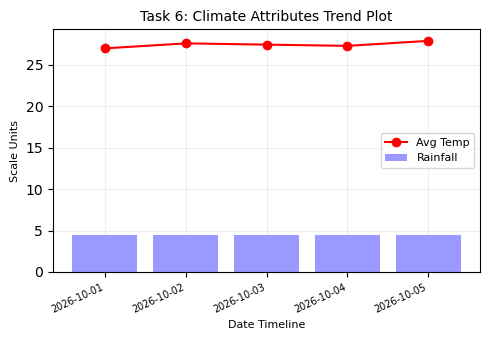

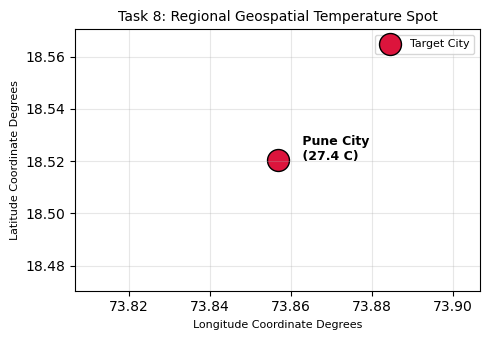

In [9]:
# task 6: line chart representing temperature changes and precipitation variations
plt.figure(figsize=(5, 3.5))
plt.plot(daily_summary['Date_Day'], daily_summary['Temperature_C'], marker='o', color='red', label='Avg Temp')
plt.bar(daily_summary['Date_Day'], daily_summary['Precipitation_Mm'], color='blue', alpha=0.4, label='Rainfall')
plt.title('Task 6: Climate Attributes Trend Plot', fontsize=10)
plt.xlabel('Date Timeline', fontsize=8)
plt.ylabel('Scale Units', fontsize=8)
plt.xticks(rotation=25, ha='right', fontsize=7)
plt.legend(fontsize=8)
plt.grid(True, alpha=0.2)
plt.tight_layout()
plt.show()
# --- task 8: incorporate geographical information map simulation ---
lat_pune, lon_pune = 18.5204, 73.8567
plt.figure(figsize=(5, 3.5))
plt.scatter([lon_pune], [lat_pune], color='crimson', s=250, edgecolor='black', label='Target City')
plt.text(lon_pune + 0.005, lat_pune, f" Pune City\n ({mean_t:.1f} C)", fontsize=9, weight='bold')
plt.title('Task 8: Regional Geospatial Temperature Spot', fontsize=10)
plt.xlabel('Longitude Coordinate Degrees', fontsize=8)
plt.ylabel('Latitude Coordinate Degrees', fontsize=8)
plt.xlim(lon_pune - 0.05, lon_pune + 0.05)
plt.ylim(lat_pune - 0.05, lat_pune + 0.05)
plt.grid(True, alpha=0.3)
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

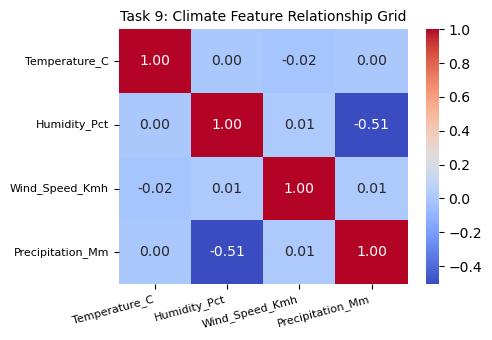

In [10]:
# task 9: explore relationships between weather parameters using correlation heatmaps
plt.figure(figsize=(5, 3.5))
corr_matrix = df[['Temperature_C', 'Humidity_Pct', 'Wind_Speed_Kmh', 'Precipitation_Mm']].corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", cbar=True)
plt.title('Task 9: Climate Feature Relationship Grid', fontsize=10)
plt.xticks(rotation=15, ha='right', fontsize=8)
plt.yticks(fontsize=8)
plt.tight_layout() # removes empty blank padding margins to minimize sheet counts
plt.show()